# Live PMC interaction analysis

The **detached CLI generates all data**. This notebook only reads its existing SQLite checkpoints and cached text. It contains no discovery, retrieval, NER, model inference, retry, export, process-control, or pipeline-construction calls. SQLite opens with `mode=ro` and `query_only=ON`, so analysis connections cannot write to the checkpoint database.

Run **all cells** to take a fresh snapshot and analyze whatever the pilot and full run have produced so far. Each refresh closes its database connection before displaying results, so it does not keep a read transaction open while you inspect plots. The notebook can run while the CLI is processing, and it needs only pandas, matplotlib, and an IPython/Jupyter environment; MLX, model weights, NCBI credentials, and network access are not required.

The default publication window is 2016-11-03 through 2026-11-03. Model-predicted interactions require expert review. No precision, recall, F1, or recovery rate against biological truth is calculated here because this corpus has no labeled truth set.

In [8]:
from contextlib import closing
from datetime import datetime, timezone
from pathlib import Path
import gzip
import hashlib
import json
import sqlite3

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Resolve the default run from the notebook directory or the repository root.
# For another run, replace OUTPUT_DIR with its absolute path.
_repository_candidates = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next((p for p in _repository_candidates if (p / "src/dgilit/pmc_pipeline.py").is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Run from this checkout, or configure REPO_ROOT explicitly.")
OUTPUT_DIR = REPO_ROOT / "data/pmc_last10years_2016-11-03_2026-11-03"

# These filters affect the evidence browser only; summary tables remain global.
BROWSER_COHORT = "all"       # "all", "pilot", or "beyond_pilot"
GENE_FILTER = ""             # Case-insensitive substring of normalized gene label
DRUG_FILTER = ""             # Case-insensitive substring of normalized drug label
DISPLAY_LIMIT = 50           # Evidence page size and maximum failure rows shown
EVIDENCE_OFFSET = 0           # 0 = first page; 50 = second page when DISPLAY_LIMIT=50
SELECTED_TASK_ID = None       # Any saved active task ID; independent of browser filters/page

print(f"Reading existing CLI checkpoints: {OUTPUT_DIR}")

Reading existing CLI checkpoints: /Users/mjc014/Documents/repo/git/dgilits/dgilit4/dgiLIT/data/pmc_last10years_2016-11-03_2026-11-03


## 1. Refresh a read-only snapshot

Discovery may still be running, the pilot may be incomplete, or most articles may not yet have been retrieved. All are valid analysis states. Queries aggregate within SQLite and return compact summaries and bounded previews, rather than loading the article/task corpus into memory. Large runs can still take time to aggregate; refresh manually when needed.

**Pilot** means `articles.pilot = 1`; **Beyond pilot** contains the remaining discovered articles; **All** includes both. A snapshot represents saved work, not a guarantee that the process is currently alive. Full-run inference estimates appear only after the CLI saves the pilot report.

In [9]:
def read_snapshot(output, cohort="all", gene="", drug="", limit=50, offset=0):
    if cohort not in {"all", "pilot", "beyond_pilot"}:
        raise ValueError("cohort must be all, pilot, or beyond_pilot")
    if not isinstance(limit, int) or isinstance(limit, bool) or not 1 <= limit <= 1000:
        raise ValueError("limit must be an integer between 1 and 1000")
    if not isinstance(offset, int) or isinstance(offset, bool) or offset < 0:
        raise ValueError("offset must be a non-negative integer")
    database = Path(output).resolve() / "state.sqlite"
    if not database.is_file():
        raise FileNotFoundError(f"No existing CLI checkpoint at {database}. This notebook does not create runs.")
    snapshot = {"read_started_at": datetime.now(timezone.utc).isoformat()}
    # Read the live WAL safely; immutable=1 would incorrectly ignore active WAL data.
    with closing(sqlite3.connect(database.as_uri() + "?mode=ro", uri=True, timeout=10)) as db:
        db.execute("PRAGMA query_only=ON")
        db.execute("BEGIN")
        try:
            def frame(sql, params=()):
                return pd.read_sql_query(sql, db, params=params)
            snapshot["metadata"] = {key: json.loads(value) for key, value in db.execute(
                "SELECT key,value FROM meta WHERE key IN ('config','query','discovery_complete',"
                "'discovery_started_at','discovery_finished_at','pilot_report','last_run','execution_fingerprint')"
            )}
            snapshot["inventory"] = frame("""
                SELECT CASE WHEN pilot=1 THEN 'Pilot' ELSE 'Beyond pilot' END cohort,
                       status,coalesce(coverage,'not_fetched') coverage,count(*) articles
                FROM articles GROUP BY pilot,status,coalesce(coverage,'not_fetched')
            """)
            snapshot["partitions"] = frame("SELECT status,count(*) partitions FROM partitions GROUP BY status")
            active = "FROM tasks t JOIN articles a ON a.pmcid=t.pmcid AND a.text_hash=t.article_hash "
            snapshot["tasks"] = frame("""
                SELECT CASE WHEN a.pilot=1 THEN 'Pilot' ELSE 'Beyond pilot' END cohort,
                       t.status,count(*) tasks,
                       sum(CASE WHEN t.status='done' AND json_extract(t.result,'$.interaction')=1 THEN 1 ELSE 0 END) positive,
                       sum(CASE WHEN t.status='done' AND json_extract(t.result,'$.interaction')=0 THEN 1 ELSE 0 END) negative,
                       avg(t.elapsed_seconds) mean_elapsed_seconds
            """ + active + " GROUP BY a.pilot,t.status")
            # Match the CLI's active-text, concept-ID grouping and conservative
            # negative policy: incomplete article processing cannot imply negative.
            pairs_cte = """
                WITH pairs AS (
                    SELECT t.pmcid,a.pilot,a.status article_status,t.drug_id,t.gene_id,
                           min(t.drug) drug,min(t.gene) gene,count(*) contexts,
                           sum(CASE WHEN t.status='done' AND json_extract(t.result,'$.interaction')=1 THEN 1 ELSE 0 END) positive_contexts,
                           sum(CASE WHEN t.status='done' AND json_extract(t.result,'$.interaction')=0 THEN 1 ELSE 0 END) negative_contexts,
                           sum(t.status!='done') unresolved_contexts
            """ + active + """ GROUP BY t.pmcid,t.drug_id,t.gene_id
                ), labeled AS (
                    SELECT *,CASE WHEN positive_contexts>0 THEN 'positive'
                        WHEN negative_contexts=contexts AND article_status IN ('complete','complete_partial') THEN 'negative'
                        ELSE 'unresolved' END pair_status FROM pairs
                )
            """
            snapshot["pairs"] = frame(pairs_cte + """
                SELECT CASE WHEN pilot=1 THEN 'Pilot' ELSE 'Beyond pilot' END cohort,
                       pair_status,count(*) article_pairs,count(DISTINCT pmcid) articles,
                       sum(CASE WHEN unresolved_contexts>0 OR article_status NOT IN ('complete','complete_partial') THEN 1 ELSE 0 END) pairs_in_incomplete_work
                FROM labeled GROUP BY pilot,pair_status
            """)
            snapshot["top_interactions"] = frame(pairs_cte + """
                SELECT drug_id,gene_id,min(drug) drug,min(gene) gene,
                       count(DISTINCT pmcid) supporting_articles,
                       sum(CASE WHEN pilot=1 THEN 1 ELSE 0 END) pilot_articles,
                       sum(CASE WHEN pilot!=1 THEN 1 ELSE 0 END) beyond_pilot_articles,
                       sum(positive_contexts) supporting_contexts
                FROM labeled WHERE pair_status='positive'
                GROUP BY drug_id,gene_id ORDER BY supporting_articles DESC,drug,gene LIMIT 20
            """)
            snapshot["top_genes"] = frame(pairs_cte + """
                SELECT gene_id,min(gene) gene,count(DISTINCT pmcid) supporting_articles,
                       count(*) positive_article_pairs FROM labeled WHERE pair_status='positive'
                GROUP BY gene_id ORDER BY supporting_articles DESC,gene LIMIT 20
            """)
            snapshot["top_drugs"] = frame(pairs_cte + """
                SELECT drug_id,min(drug) drug,count(DISTINCT pmcid) supporting_articles,
                       count(*) positive_article_pairs FROM labeled WHERE pair_status='positive'
                GROUP BY drug_id ORDER BY supporting_articles DESC,drug LIMIT 20
            """)
            filters = """
                WHERE t.status='done' AND json_extract(t.result,'$.interaction')=1
                  AND (?='all' OR (?='pilot' AND a.pilot=1) OR (?='beyond_pilot' AND a.pilot!=1))
                  AND (?='' OR instr(lower(t.gene),lower(?))>0)
                  AND (?='' OR instr(lower(t.drug),lower(?))>0)
            """
            browser_params = (cohort,cohort,cohort,gene,gene,drug,drug)
            snapshot["evidence_matches"] = int(frame(
                "SELECT count(*) matches " + active + filters, browser_params
            ).iloc[0]["matches"])
            snapshot["evidence_offset"] = offset
            snapshot["evidence_limit"] = limit
            snapshot["evidence"] = frame("""
                SELECT t.id task_id,t.pmcid,a.pmid,a.title,
                       CASE WHEN a.pilot=1 THEN 'Pilot' ELSE 'Beyond pilot' END cohort,
                       a.status article_status,a.coverage,t.drug_id,t.drug,t.gene_id,t.gene,
                       t.section_id,t.section_index,t.context_start,t.context_end,t.context_hash,
                       json_extract(s.metadata,'$.section_type') section_type,
                       json_extract(s.metadata,'$.label') section_label,
                       json_extract(s.metadata,'$.parent_label') parent_label,
                       json_extract(s.metadata,'$.source') section_source,
                       json_extract(t.result,'$.evidence') evidence,
                       json_extract(t.result,'$.evidence_in_context') evidence_in_context,
                       json_extract(t.result,'$.interaction_type') interaction_type,
                       json_extract(t.result,'$.directionality') directionality,
                       json_extract(t.result,'$.model_id') model_id,
                       json_extract(t.result,'$.prompt_version') prompt_version,t.updated_at
            """ + active + " LEFT JOIN sections s ON s.id=t.section_id " + filters +
                " ORDER BY t.updated_at DESC,t.id LIMIT ? OFFSET ?",
                (*browser_params,limit,offset))
            snapshot["failure_counts"] = frame("""
                SELECT stage,resolved,count(*) events FROM failures GROUP BY stage,resolved
            """)
            snapshot["failures"] = frame("""
                SELECT stage,pmcid,item_id,error,recorded_at FROM failures WHERE resolved=0
                ORDER BY id DESC LIMIT ?
            """, (limit,))
        finally:
            db.rollback()
    snapshot["read_finished_at"] = datetime.now(timezone.utc).isoformat()
    return snapshot


# Rerun this cell and the analysis cells below to refresh from the CLI's latest data.
snapshot = read_snapshot(OUTPUT_DIR, BROWSER_COHORT, GENE_FILTER, DRUG_FILTER, DISPLAY_LIMIT, EVIDENCE_OFFSET)
metadata = snapshot["metadata"]
print(f"Snapshot read: {snapshot['read_started_at']} to {snapshot['read_finished_at']} (UTC)")
display(pd.Series({
    "Discovery complete": metadata.get("discovery_complete", False),
    "Publication start": metadata.get("config", {}).get("start"),
    "Publication end": metadata.get("config", {}).get("end"),
    "Model": metadata.get("config", {}).get("model_id"),
    "CLI last recorded state": metadata.get("last_run", {}).get("status"),
    "CLI last recorded PID": metadata.get("last_run", {}).get("pid"),
}).to_frame("Value"))
if metadata.get("pilot_report"):
    display(pd.Series(metadata["pilot_report"]).to_frame("CLI pilot report"))
else:
    print("The CLI has not saved a pilot report yet. Live results below are still available.")

Snapshot read: 2026-11-04T22:45:46.894878+00:00 to 2026-11-04T22:45:52.820448+00:00 (UTC)


,Value
Discovery complete,True
Publication start,2016-11-03
Publication end,2026-11-03
Model,mlx-community/Qwen3-14B-4bit
CLI last recorded state,running
CLI last recorded PID,16608


,CLI pilot report
sample_articles,100
corpus_articles,7765409
sample_context_tasks,4693
measured_calls,100
mean_call_seconds,12.350066
pilot_elapsed_seconds,4329.910864
estimated_corpus_context_tasks,364430644.37
estimated_inference_days,52091.925893
inventory_baseline_bytes,1236398080
sample_state_growth_bytes,13389824


## 2. Pilot and full-cohort progress

Counts include discovered papers even when they have not been retrieved. A task is one pair assessed in one context; an **article pair** is one normalized drug/gene combination within one PMCID. Repeated contexts do not inflate the article-pair count.

Positive fractions describe **model output composition**, not precision. Task completion describes execution progress, not biological recall or recovery. Pilot and beyond-pilot articles can differ in processing stage, so early differences should not be interpreted as differences in model performance.

In [10]:
COHORTS = ["Pilot", "Beyond pilot", "All"]

def cohort_counts(table, value, conditions=None):
    selected = table if conditions is None else table.loc[conditions]
    grouped = selected.groupby("cohort")[value].sum().reindex(COHORTS[:2], fill_value=0)
    return pd.Series([int(grouped.iloc[0]), int(grouped.iloc[1]), int(grouped.sum())], index=COHORTS)

inventory = snapshot["inventory"]
tasks = snapshot["tasks"]
pairs = snapshot["pairs"]
summary = pd.DataFrame(index=COHORTS)
summary["Discovered articles"] = cohort_counts(inventory, "articles")
summary["Retrieval attempted"] = cohort_counts(inventory, "articles", inventory["coverage"] != "not_fetched")
summary["Articles with usable text"] = cohort_counts(inventory, "articles", inventory["coverage"].isin(["full_text", "abstract_only"]))
summary["Full-text articles"] = cohort_counts(inventory, "articles", inventory["coverage"] == "full_text")
summary["Abstract-only articles"] = cohort_counts(inventory, "articles", inventory["coverage"] == "abstract_only")
summary["Articles with processing complete"] = cohort_counts(inventory, "articles", inventory["status"].isin(["complete", "complete_partial", "no_candidates", "no_text"]))
summary["Failed articles"] = cohort_counts(inventory, "articles", inventory["status"] == "failed")
summary["Context tasks created"] = cohort_counts(tasks, "tasks")
summary["Context tasks completed"] = cohort_counts(tasks, "tasks", tasks["status"] == "done")
summary["Positive contexts"] = cohort_counts(tasks, "positive")
summary["Negative contexts"] = cohort_counts(tasks, "negative")
summary["Article pairs assessed/queued"] = cohort_counts(pairs, "article_pairs")
summary["Positive article pairs"] = cohort_counts(pairs, "article_pairs", pairs["pair_status"] == "positive")
summary["Negative article pairs"] = cohort_counts(pairs, "article_pairs", pairs["pair_status"] == "negative")
summary["Unresolved article pairs"] = cohort_counts(pairs, "article_pairs", pairs["pair_status"] == "unresolved")
# Each article is counted once within the positive category, regardless of pair count.
summary["Articles with positive predictions"] = cohort_counts(pairs, "articles", pairs["pair_status"] == "positive")
display(summary.T)

rates = pd.DataFrame(index=COHORTS)
rates["Retrieval attempted / discovered"] = summary["Retrieval attempted"].div(summary["Discovered articles"].replace(0, float("nan")))
rates["Completed / created context tasks"] = summary["Context tasks completed"].div(summary["Context tasks created"].replace(0, float("nan")))
rates["Positive / completed contexts"] = summary["Positive contexts"].div(summary["Context tasks completed"].replace(0, float("nan")))
display(rates.style.format("{:.2%}", na_rep="Not available"))
display(inventory.sort_values(["cohort", "status", "coverage"]).reset_index(drop=True))
display(snapshot["partitions"])

,Pilot,Beyond pilot,All
Discovered articles,100,7765309,7765409
Retrieval attempted,100,175,275
Articles with usable text,100,149,249
Full-text articles,83,59,142
Abstract-only articles,17,90,107
Articles with processing complete,74,166,240
Failed articles,11,9,20
Context tasks created,4693,551,5244
Context tasks completed,2019,512,2531
Positive contexts,90,44,134


,Retrieval attempted / discovered,Completed / created context tasks,Positive / completed contexts
Pilot,100.00%,43.02%,4.46%
Beyond pilot,0.00%,92.92%,8.59%
All,0.00%,48.26%,5.29%


,cohort,status,coverage,articles
0,Beyond pilot,complete,abstract_only,5
1,Beyond pilot,complete,full_text,7
2,Beyond pilot,failed,full_text,9
3,Beyond pilot,no_candidates,abstract_only,85
4,Beyond pilot,no_candidates,full_text,43
5,Beyond pilot,no_text,no_text,26
6,Beyond pilot,pending,not_fetched,7765134
7,Pilot,complete,abstract_only,1
8,Pilot,complete,full_text,11
9,Pilot,failed,abstract_only,1


,status,partitions
0,complete,1807
1,split,1843


## 3. Identified interactions and supporting papers

Rank normalized interactions, genes, and drugs by the number of **distinct supporting articles**. These rankings describe the processed portion of the corpus. An article-level positive may already be visible while other contexts from the same paper remain unfinished.

,drug_id,gene_id,drug,gene,supporting_articles,pilot_articles,beyond_pilot_articles,supporting_contexts
0,normalize.therapy.iuphar.ligand:6274,normalize.gene.hgnc:402,4-hydroxynonenal,ALDH1A1,1,0,1,1
1,normalize.therapy.iuphar.ligand:6274,normalize.gene.hgnc:404,4-hydroxynonenal,ALDH2,1,0,1,2
2,normalize.therapy.iuphar.ligand:6274,normalize.gene.hgnc:6881,4-hydroxynonenal,MAPK8,1,0,1,1
3,normalize.therapy.chembl:CHEMBL211501,normalize.gene.hgnc:404,ANTIMYCIN A,ALDH2,1,0,1,1
4,normalize.therapy.chembl:CHEMBL211501,normalize.gene.hgnc:620,ANTIMYCIN A,APP,1,0,1,1
5,normalize.therapy.drugbank:DB16829,normalize.gene.hgnc:7545,Abscisic Acid,MYB,1,1,0,1
6,normalize.therapy.chembl:CHEMBL327919,normalize.gene.hgnc:404,BENOMYL,ALDH2,1,0,1,1
7,normalize.therapy.chembl:CHEMBL267373,normalize.gene.hgnc:358,BENZAMIDE,AIP,1,1,0,1
8,normalize.therapy.chembl:CHEMBL267373,normalize.gene.ncbigene:100187907,BENZAMIDE,TRAP,1,1,0,1
9,normalize.therapy.drugbank:DB02527,normalize.gene.hgnc:391,Cyclic adenosine monophosphate,AKT1,1,1,0,1


,gene_id,gene,supporting_articles,positive_article_pairs
0,normalize.gene.hgnc:3942,MTOR,2,2
1,normalize.gene.hgnc:7545,MYB,2,3
2,normalize.gene.hgnc:9606,PTH,2,4
3,normalize.gene.hgnc:84,ACACA,1,1
4,normalize.gene.hgnc:358,AIP,1,2
5,normalize.gene.hgnc:391,AKT1,1,3
6,normalize.gene.hgnc:402,ALDH1A1,1,3
7,normalize.gene.hgnc:404,ALDH2,1,11
8,normalize.gene.hgnc:620,APP,1,1
9,normalize.gene.hgnc:644,AR,1,1


,drug_id,drug,supporting_articles,positive_article_pairs
0,normalize.therapy.drugbank:DB02527,Cyclic adenosine monophosphate,3,5
1,normalize.therapy.drugbank:DB02338,NADPH,2,4
2,normalize.therapy.rxcui:1895,calcium,2,3
3,normalize.therapy.rxcui:1316581,calcium ion,2,2
4,normalize.therapy.rxcui:3628,dopamine,2,4
5,normalize.therapy.iuphar.ligand:6274,4-hydroxynonenal,1,3
6,normalize.therapy.chembl:CHEMBL211501,ANTIMYCIN A,1,2
7,normalize.therapy.drugbank:DB16829,Abscisic Acid,1,1
8,normalize.therapy.chembl:CHEMBL327919,BENOMYL,1,1
9,normalize.therapy.chembl:CHEMBL267373,BENZAMIDE,1,2


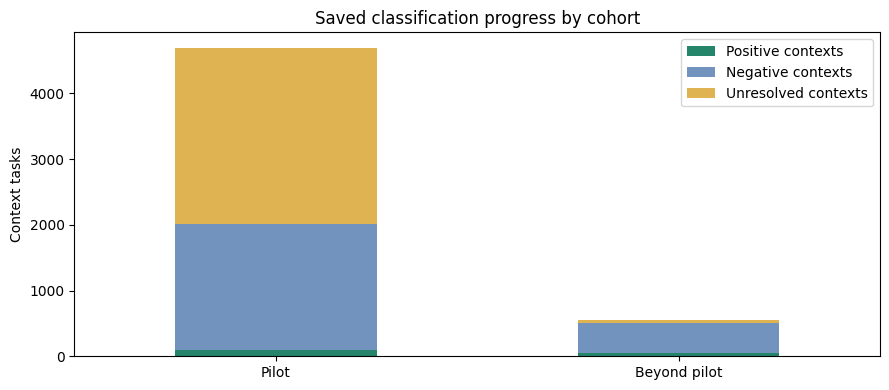

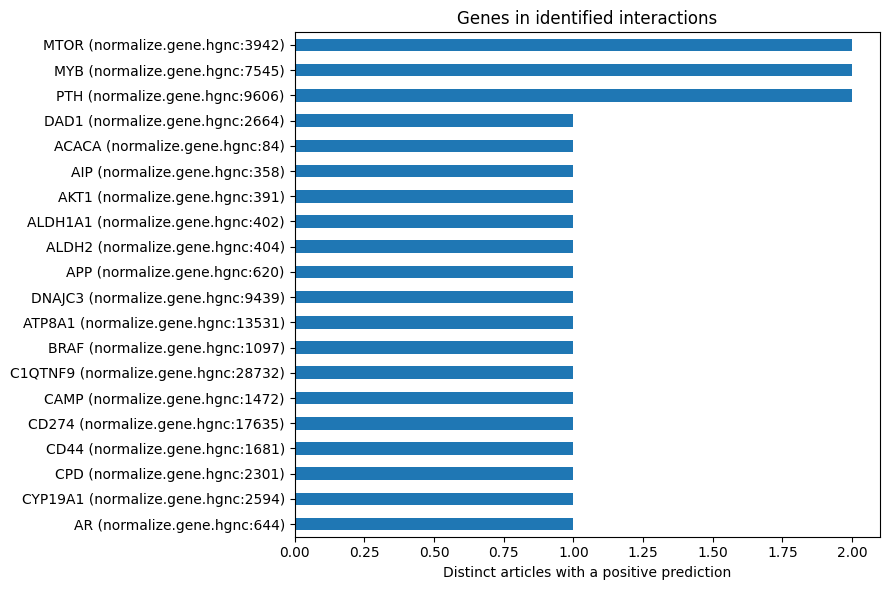

In [11]:
if snapshot["top_interactions"].empty:
    print("No positive interactions have been saved in the current snapshot. Refresh after the CLI progresses.")
else:
    display(snapshot["top_interactions"])
    display(snapshot["top_genes"])
    display(snapshot["top_drugs"])

if int(summary.loc["All", "Context tasks created"]):
    task_plot = summary.loc[COHORTS[:2], ["Positive contexts", "Negative contexts"]].copy()
    task_plot["Unresolved contexts"] = summary.loc[COHORTS[:2], "Context tasks created"] - summary.loc[COHORTS[:2], "Context tasks completed"]
    ax = task_plot.plot.bar(stacked=True, figsize=(9, 4), color=["#24856b", "#7393bf", "#dfb352"])
    ax.set_ylabel("Context tasks")
    ax.set_title("Saved classification progress by cohort")
    ax.tick_params(axis="x", rotation=0)
    plt.tight_layout()
    plt.show()

if not snapshot["top_genes"].empty:
    genes = snapshot["top_genes"].sort_values("supporting_articles").copy()
    genes["label"] = genes["gene"] + " (" + genes["gene_id"] + ")"
    ax = genes.plot.barh(x="label", y="supporting_articles", legend=False, figsize=(9, max(3, len(genes) * 0.3)))
    ax.set_xlabel("Distinct articles with a positive prediction")
    ax.set_ylabel("")
    ax.set_title("Genes in identified interactions")
    plt.tight_layout()
    plt.show()

## 4. Browse positive evidence across the processed corpus

`BROWSER_COHORT = "all"` includes **both pilot and non-pilot articles**, including positive contexts already saved from articles whose other tasks are unfinished. It does not require the entire cohort to finish. Global summaries and rankings always use all saved active results, even when browser filters are changed.

Set `GENE_FILTER` or `DRUG_FILTER` for a case-insensitive label search. `DISPLAY_LIMIT` sets the page size; `EVIDENCE_OFFSET` selects the page (for 50-row pages: 0, 50, 100, ...). Refresh the snapshot after changing these values. The table reports the total matching positive contexts, so a short preview is not mistaken for the full result set. Newly saved results can shift page positions between refreshes; task IDs remain stable.

Each row is a positive **context task**; an article pair can have several supporting rows. Copy a `task_id` into `SELECTED_TASK_ID` to inspect that entry. Direct lookup works beyond this page and independently of the cohort/gene/drug filters.

In [12]:
evidence = snapshot["evidence"]
matched = snapshot["evidence_matches"]
start = snapshot["evidence_offset"]
print(f"Evidence scope: {BROWSER_COHORT}; matching positive contexts across the processed corpus: {matched:,}")
if evidence.empty:
    print("No rows on this page. If matches exist, lower EVIDENCE_OFFSET; otherwise adjust filters or refresh later.")
else:
    print(f"Showing matches {start + 1:,}–{start + len(evidence):,} of {matched:,}.")
    with pd.option_context("display.max_colwidth", 180, "display.max_rows", DISPLAY_LIMIT):
        display(evidence)


Evidence scope: all; matching positive contexts across the processed corpus: 134
Showing matches 1–50 of 134.


,task_id,pmcid,pmid,title,cohort,article_status,coverage,drug_id,drug,gene_id,...,section_label,parent_label,section_source,evidence,evidence_in_context,interaction_type,directionality,model_id,prompt_version,updated_at
0,74f185c95938681f43cb786c6fbfead5f2e6b9f273cfbb1c4d562fd281a57f6b,PMC10401459,37547582,Novel insights regarding the role of noncoding RNAs in diabetes,Pilot,prepared,full_text,normalize.therapy.drugbank:DB02967,N-Ethylmaleimide,normalize.gene.hgnc:592,...,miRNAs as glucose homeostasis regulators,ROLES OF miRNAs IN DM,pmc,"miR-200 also induces expression of proapoptotic genes in both T1DM and T2DM by suppressing Xiap, a caspase inhibitor, and Dnajc3, a β-cell heat shock protein, while activating ...",1,regulation,inhibiting,mlx-community/Qwen3-14B-4bit,v2,2026-11-04T22:41:28.096194+00:00
1,6b7d152d5c418770a3aafd1179b1f13196bbfd2f8e91989609ae37dd0023f8d5,PMC10401459,37547582,Novel insights regarding the role of noncoding RNAs in diabetes,Pilot,prepared,full_text,normalize.therapy.rxcui:6400,linoleic acid,normalize.gene.hgnc:14929,...,miRNAs AS POTENTIAL THERAPEUTIC TARGETS IN DIABETES TREATMENT,None,pmc,oligonucleotide-mediated downregulation of miR-181 in DIO mice increased levels of SIRT1 and ameliorated insulin sensitivity and glucose homeostasis[ 245 ].,1,regulation,upregulation,mlx-community/Qwen3-14B-4bit,v2,2026-11-04T22:35:19.110432+00:00
2,643c84bdc8b5b7617b820825db884bfcb43bc58e38a08ab5242b2955a326fcd9,PMC10401459,37547582,Novel insights regarding the role of noncoding RNAs in diabetes,Pilot,prepared,full_text,normalize.therapy.rxcui:10114,streptozocin,normalize.gene.hgnc:31628,...,miRNAs as glucose homeostasis regulators,ROLES OF miRNAs IN DM,pmc,"miR-30d, miR-184, miR-203, miR-210, miR-338–3p and miR-383 had significantly decreased levels[ 44 - 46 ]",1,expression regulation,inhibiting,mlx-community/Qwen3-14B-4bit,v2,2026-11-04T21:37:42.285306+00:00
3,584ee64a8f22de8a6bc3c4465b59044ea402aec601fb5800f68460e99ae15b0f,PMC10401459,37547582,Novel insights regarding the role of noncoding RNAs in diabetes,Pilot,prepared,full_text,normalize.therapy.rxcui:10114,streptozocin,normalize.gene.hgnc:9439,...,miRNAs as glucose homeostasis regulators,ROLES OF miRNAs IN DM,pmc,"miR-200 also induces expression of proapoptotic genes in both T1DM and T2DM by suppressing Xiap, a caspase inhibitor, and Dnajc3, a β-cell heat shock protein, while activating ...",1,regulation,inhibiting,mlx-community/Qwen3-14B-4bit,v2,2026-11-04T18:56:38.530167+00:00
4,45848a7e48c026e8d6309d86e36e2b50c85ec89ccc35ec2123c74fca092abbad,PMC10401459,37547582,Novel insights regarding the role of noncoding RNAs in diabetes,Pilot,prepared,full_text,normalize.therapy.rxcui:6400,linoleic acid,normalize.gene.hgnc:31601,...,miRNAs AS POTENTIAL THERAPEUTIC TARGETS IN DIABETES TREATMENT,None,pmc,"CLA treatment altered the expression of miRNAs related to adipocyte differentiation, lipid metabolism, and obesity, such as miR-143, miR-107, miR-222, miR-103 and miR-221",1,regulation,unclear,mlx-community/Qwen3-14B-4bit,v2,2026-11-04T18:49:09.191608+00:00
5,3b017673b233397a7b359f2d6400df2204d0720a4bb23233fafe529ffd0f31cb,PMC10401459,37547582,Novel insights regarding the role of noncoding RNAs in diabetes,Pilot,prepared,full_text,normalize.therapy.rxcui:10114,streptozocin,normalize.gene.hgnc:31555,...,miRNAs as glucose homeostasis regulators,ROLES OF miRNAs IN DM,pmc,decreased expression of miR-184 was confirmed in an independent study using the islets of mice on a high-fat diet[ 48 ].,1,expression regulation,inhibiting,mlx-community/Qwen3-14B-4bit,v2,2026-11-04T18:44:35.327633+00:00
6,38be86d6993ff303710a3ac8473936e5e607986d9ce6ab5f473619f4db4de6a6,PMC10401459,37547582,Novel insights regarding the role of noncoding RNAs in diabetes,Pilot,prepared,full_text,normalize.therapy.rxcui:6400,linoleic acid,normalize.gene.hgnc:31530,...,miRNAs AS POTENTIAL THERAPEUTIC TARGETS IN DIABETES TREATMENT,None,pmc,"CLA treatment altered the expression of miRNAs related to adipocy

### Inspect a single entry in detail

Set `SELECTED_TASK_ID` to **any active saved task ID**, then run the detail cell below. It queries the entire current checkpoint directly, without applying browser filters, page size, or offset. Leave it unset to select the first positive row on the current page. Explicit lookup also supports negative, failed, or unfinished tasks for review.

The detail view shows the article and cohort, normalized concept IDs, task status, section provenance, full evidence, raw structured classifier result, generation statistics, and the status of other contexts for the same article pair. This is a fresh read and can be newer than the summary snapshot.

The full source context is shown only if it remains in the CLI's text cache and its hash matches the task. An evicted or changed cache does not trigger retrieval or inference.

In [13]:
def read_entry(output, task_id):
    if not isinstance(task_id, str) or not task_id.strip():
        raise ValueError("Provide a non-empty saved task ID")
    database = Path(output).resolve() / "state.sqlite"
    if not database.is_file():
        raise FileNotFoundError(f"No existing CLI checkpoint at {database}")
    with closing(sqlite3.connect(database.as_uri() + "?mode=ro", uri=True, timeout=10)) as db:
        db.execute("PRAGMA query_only=ON")
        db.execute("BEGIN")
        try:
            task = pd.read_sql_query("""
                SELECT t.*,a.pmid,a.title,a.publication_year,a.license,
                       CASE WHEN a.pilot=1 THEN 'Pilot' ELSE 'Beyond pilot' END cohort,
                       a.status article_status,a.coverage,s.metadata section_metadata
                FROM tasks t JOIN articles a ON a.pmcid=t.pmcid AND a.text_hash=t.article_hash
                LEFT JOIN sections s ON s.id=t.section_id WHERE t.id=?
            """, db, params=(task_id.strip(),))
            if task.empty:
                return None
            row = task.iloc[0]
            pair_contexts = pd.read_sql_query("""
                SELECT t.status,count(*) contexts,
                       sum(CASE WHEN t.status='done' AND json_extract(t.result,'$.interaction')=1 THEN 1 ELSE 0 END) positive,
                       sum(CASE WHEN t.status='done' AND json_extract(t.result,'$.interaction')=0 THEN 1 ELSE 0 END) negative
                FROM tasks t WHERE t.pmcid=? AND t.article_hash=? AND t.drug_id=? AND t.gene_id=?
                GROUP BY t.status
            """, db, params=(row["pmcid"],row["article_hash"],row["drug_id"],row["gene_id"]))
            return {"task":row,"pair_contexts":pair_contexts,"read_at":datetime.now(timezone.utc).isoformat()}
        finally:
            db.rollback()


entry_id = SELECTED_TASK_ID
if entry_id is None and not evidence.empty:
    entry_id = evidence.iloc[0]["task_id"]
entry = read_entry(OUTPUT_DIR, entry_id) if entry_id is not None else None
if entry_id is None:
    print("Enter SELECTED_TASK_ID, or choose an evidence page containing positive results.")
elif entry is None:
    print("Task ID was not found among active saved results. Check the ID; it may refer to superseded article text.")
else:
    task = entry["task"]
    print(f"Entry read at {entry['read_at']} (UTC); cohort: {task['cohort']}; task status: {task['status']}")
    with pd.option_context("display.max_colwidth", None):
        display(task.drop(labels=["result", "section_metadata"]).to_frame("Saved task and article"))
    print("Section provenance:")
    display(pd.Series(json.loads(task["section_metadata"]) if pd.notna(task["section_metadata"]) else {}, dtype=object).to_frame("Value"))
    print("All saved contexts for this article/drug/gene pair:")
    display(entry["pair_contexts"])
    if pd.notna(task["result"]):
        result = json.loads(task["result"])
        print("Complete classifier result and generation statistics:")
        print(json.dumps(result, indent=2, ensure_ascii=False))
        if result.get("evidence"):
            print("Full saved evidence quote:")
            print(result["evidence"])
    else:
        print("No completed classifier result is saved for this task.")
    cached_file = OUTPUT_DIR / "text_cache" / f"{task['pmcid']}.json.gz"
    try:
        with gzip.open(cached_file, "rt") as handle:
            cached_article = json.load(handle)
        text = cached_article["sections"][int(task["section_index"])]["text"]
        context = text[int(task["context_start"]):int(task["context_end"])]
        context_hash = hashlib.sha256(json.dumps(context, sort_keys=True, ensure_ascii=False).encode()).hexdigest()
        if context_hash == task["context_hash"]:
            print("Complete cached source context (hash verified):")
            print(context)
        else:
            print("Cached source differs from this saved task; saved evidence/provenance remain available above.")
    except FileNotFoundError:
        print("Source text is no longer cached; saved evidence/provenance remain available above.")
    except (OSError, ValueError, KeyError, IndexError) as exc:
        print(f"Cached context could not be read ({type(exc).__name__}); no retrieval was attempted.")

Entry read at 2026-11-04T22:45:53.081396+00:00 (UTC); cohort: Pilot; task status: done


,Saved task and article
id,74f185c95938681f43cb786c6fbfead5f2e6b9f273cfbb1c4d562fd281a57f6b
pmcid,PMC10401459
article_hash,66ea3ba97f40a305ffde82099083083f2a93245386dbc90710203be53c26f08b
section_id,edf4314ccb6e01b230def467d2c3203da2d22531049af8614feb0d819ced0d85
section_index,3
context_start,0
context_end,7355
context_hash,0d753861194de665cd38b814daaf1570b1530412edcf572ec90b1eddfede5194
drug_id,normalize.therapy.drugbank:DB02967
gene_id,normalize.gene.hgnc:592


Section provenance:


,Value
section_type,body
label,miRNAs as glucose homeostasis regulators
section_id,None
parent_label,ROLES OF miRNAs IN DM
source,pmc


All saved contexts for this article/drug/gene pair:


,status,contexts,positive,negative
0,done,1,1,0


Complete classifier result and generation statistics:
{
  "drug": "N-Ethylmaleimide",
  "gene": "XIAP",
  "interaction": true,
  "evidence": "miR-200 also induces expression of proapoptotic genes in both T1DM and T2DM by suppressing Xiap, a caspase inhibitor, and Dnajc3, a β-cell heat shock protein, while activating the tumor suppressor protein Trp53[ 66 ].",
  "interaction_type": "regulation",
  "directionality": "inhibiting",
  "error_message": null,
  "evidence_in_context": true,
  "model_id": "mlx-community/Qwen3-14B-4bit",
  "prompt_version": "v2",
  "temperature": 0,
  "enable_thinking": false,
  "generation_stats": {
    "prompt_tokens": 2613,
    "generation_tokens": 128,
    "elapsed_seconds": 21.756285957999353,
    "generation_tokens_per_second": 15.682164748687299,
    "end_to_end_tokens_per_second": 5.883357124791649
  }
}
Full saved evidence quote:
miR-200 also induces expression of proapoptotic genes in both T1DM and T2DM by suppressing Xiap, a caspase inhibitor, and Dna

## 5. Coverage and unresolved failures

A failed request or model invocation is not a negative interaction. Failure counts are events, not necessarily unique papers. Resolved historical events remain in the checkpoint log. Missing text, missing normalized candidates, and pending work constrain which interactions are currently visible.

In [14]:
if snapshot["failure_counts"].empty:
    print("No failure events recorded in this snapshot.")
else:
    display(snapshot["failure_counts"])
if not snapshot["failures"].empty:
    with pd.option_context("display.max_colwidth", 180):
        display(snapshot["failures"])
else:
    print("No unresolved failure events in this snapshot.")

print("Refresh by rerunning all cells. Data generation and retries remain owned by the CLI.")

,stage,resolved,events
0,classification,0,160
1,discovery,1,26


,stage,pmcid,item_id,error,recorded_at
0,classification,PMC10401459,761ec573490bb130fd5aaec0ecc36b65af81ae7528a6cd29994ba0ee78079cd6,Positive classification lacks a verifiable direct evidence quote,2026-11-04T22:42:30.227074+00:00
1,classification,PMC10401459,661a06dd1e547bc92b6ef29eef4ff0b957fd168676615998c10d18efc3ace7d4,Positive classification lacks a verifiable direct evidence quote,2026-11-04T22:28:13.128254+00:00
2,classification,PMC10401459,6577786ac9a42f35b5303625e188f37473cc029dc5cf608b8d2071591d4da6e5,Positive classification lacks a verifiable direct evidence quote,2026-11-04T22:02:08.439828+00:00
3,classification,PMC10401459,61cd7bf0e5db2d0e72d4f9e4e611fcbab775ccf5306c02f5de52f3a5ae643f04,Positive classification lacks a verifiable direct evidence quote,2026-11-04T21:14:18.937009+00:00
4,classification,PMC10401459,3b16396a9547ee43f021098b95792e9ec718a858230f1c5ab74eb88b7a308ecf,Positive classification lacks a verifiable direct evidence quote,2026-11-04T18:45:22.681423+00:00
5,classification,PMC10401459,334714a49ffdb40cfdcc119485db02f4f5c8932b160c3370d10018fb62d068d7,Positive classification lacks a verifiable direct evidence quote,2026-11-04T18:40:34.510095+00:00
6,classification,PMC10401459,307f9c3af2d6a98ee9247749591b7403045383de9630de46fa33c866010365ed,Positive classification lacks a verifiable direct evidence quote,2026-11-04T18:39:28.508811+00:00
7,classification,PMC10401459,0b2b1a17620fe3285f9d49efb281654eedb0c3ced22122fc1d011ec0301ac5bb,Positive classification lacks a verifiable direct evidence quote,2026-11-04T18:19:11.438687+00:00
8,classification,PMC10401459,0802e0bb20cd7319f71ad9cba593d79fecb13f9927b09e053a6eb7f5bde0079f,Positive classification lacks a verifiable direct evidence quote,2026-11-04T18:16:53.289318+00:00
9,classification,PMC9841042,f3e4134e776fc9e9f4ff0fd6dc6c9306ada6e51570e23d35b87ff335767e6d89,Positive classification lacks a verifiable direct evidence quote,2026-11-04T18:11:26.252792+00:00


Refresh by rerunning all cells. Data generation and retries remain owned by the CLI.
